# DATA 620 – Week 4 Assignment: Centrality Measures

- **Author:** Kerwin Charles
- **Dataset:** SNAP *ego-Twitter* (Stanford Large Network Dataset Collection)
- **Builds on:** Week 3 Graph Visualization (same ego network, user `374007416`)

## Overview

The idea behind this week's assignment is that centrality measures can be used to predict
positive or negative outcomes for a node. The task is to find network data on the web that
has at least one categorical variable for every node, explain how I would load it, and
describe an outcome that could be predicted by comparing degree centrality across the
categories.

In Week 3 I worked with one Twitter ego network from SNAP. Because I already know that
network well, I am staying with it. The piece that was missing last week was a categorical
variable, and this dataset has one built in: the **circles**, which are the Twitter lists
the ego user sorted the people they follow into. Every person in the network is either on
at least one of those lists or on none of them, so every node can be labelled
**Listed** or **Unlisted**.

This notebook covers:

1. the data source and why I chose it,
2. the nodes, edges and categorical variables,
3. a high-level plan for loading the data, with a short check that the plan works,
4. how degree centrality applies to this network,
5. the hypothetical outcome I expect degree centrality to predict, and
6. the limitations of the data.

## Data source

**Where it comes from.** The *Social circles: Twitter* dataset is published by the Stanford
Network Analysis Project (SNAP). It was collected for a 2012 study on discovering social
circles, using Twitter data gathered from public sources. It includes the ego networks,
the circles and profile features for each user.

**Size.** Across all 973 ego networks the combined graph has **81,306 users** and
**1,768,149 directed follow edges**.

**How it is accessed.** Everything is a plain HTTP download, so it can be pulled straight
into Python:

| File on SNAP | Contents |
|---|---|
| `twitter.tar.gz` | the 973 ego networks, five files per ego (about 22 MB compressed) |
| `twitter_combined.txt.gz` | the edges from all ego networks combined |
| `readme-Ego.txt` | description of the file formats |

**Why not the live Twitter API?** In February 2023 Twitter ended free access to its API
and moved to paid tiers. Collecting a fresh follow network by snowball sampling through the
API (starting from one user and following their connections outward) is no longer
practical for a class project. The SNAP archive is a public snapshot of the same kind of
data.

**Why this dataset is a good fit**

- Every edge means the same thing ("A follows B"). Mixing different kinds of
  relationships in one network makes centrality hard to interpret.
- It is a one-mode network (users to users). Hashtags are only used as node attributes,
  not as nodes, so I avoid the two-mode (bipartite) problem, where centrality is not
  comparable across two node types.
- The circles give a categorical variable that the ego created, rather than one I have to
  invent. The IDs are anonymised, which makes them harder to interpret, but the hashtags
  and circles give the nodes meaning that plain IDs don't have.

## Nodes, edges and categorical variables

Each ego network is stored as five text files named after the ego's user ID:

| File | Format | Meaning |
|---|---|---|
| `<ego>.edges` | `a b` per line | directed edge: user **a follows b** (both followed by the ego) |
| `<ego>.circles` | `circle_id member member ...` | one line per circle (Twitter list) made by the ego |
| `<ego>.feat` | `node 0 1 0 ...` | binary features for each user |
| `<ego>.featnames` | `index name` | feature names: hashtags (`#`) and mentions (`@`) |
| `<ego>.egofeat` | `0 1 0 ...` | the ego's own features |

- **Nodes:** the users the ego follows (the *alters*). The ego is not written in the edge
  file and is assumed to follow every node. As in Week 3, I leave the ego
  out, because a node connected to everyone turns the network into a hub-and-spoke shape
  (in Week 3 it shrank the diameter from 8 to 2).
- **Edges:** directed "follows" relationships among the alters. They are unweighted.

**Categorical variables**

| Variable | Values | Built from | Every node has a value? |
|---|---|---|---|
| **List status** (primary) | Listed / Unlisted | in at least one circle vs. in none | Yes |
| Circle | circle ID (can be several) | `<ego>.circles` | Yes ("none" for Unlisted) |
| Photography tagger (secondary) | Yes / No | has `#photography`, `#photos`, `#photoshop` or `#photographers` | Yes, with a caveat (see the loading checks) |

List status is the main variable because it is complete and not ambiguous. A user can be in
several circles, so "Circle" on its own is not a single category per node; collapsing it to
Listed/Unlisted fixes that.

## Plan for loading the data

**High-level steps**

1. **Download** `twitter.tar.gz` from SNAP with `urllib` (skipped if the file is already
   on disk), and extract it into `data/twitter/`.
2. **Read the edges** of the chosen ego network into a directed `networkx` graph
   (`DiGraph`), one edge per "a follows b" line.
3. **Add every alter as a node**, including people listed in `.feat` who have no edges to
   the other alters, so nobody is silently dropped (13 such users in this network).
4. **Read the circles** and set a node attribute `list_status` = Listed or Unlisted, plus a
   `circles` attribute listing the circle IDs.
5. **Read the features**, normalise the hashtags (lower case, trailing punctuation
   removed) and set the secondary attribute `photo_tagger`.
6. **Validate**: every node has a `list_status`, every circle member is a node, and the
   group sizes are large enough to compare.
7. **Compare with the wider dataset**: count how many of the 973 ego networks use lists,
   to see how typical this ego is.

The code below carries out steps 1–7. It only checks that the data can be loaded and
labelled; it does **not** compare centrality between the groups.

In [57]:
import collections
import tarfile
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

EGO = "374007416"
DATA = Path("data")
URL = "https://snap.stanford.edu/data/twitter.tar.gz"
TARBALL = DATA / "twitter.tar.gz"
FOLDER = DATA / "twitter"
DATA.mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

In [58]:
# Step 1: download (only if missing) and extract
if not TARBALL.exists():
    print("Downloading", URL)
    urllib.request.urlretrieve(URL, TARBALL)
if not FOLDER.exists():
    with tarfile.open(TARBALL) as tar:
        tar.extractall(DATA)

files = list(FOLDER.iterdir())
egos = sorted({f.stem for f in files})
print(f"Archive size     : {TARBALL.stat().st_size / 1e6:.1f} MB")
print(f"Files extracted  : {len(files)}")
print(f"Ego networks     : {len(egos)}")
print("File types       :", sorted(collections.Counter(f.suffix for f in files)
                                   .items()))

Archive size     : 22.3 MB
Files extracted  : 4865
Ego networks     : 973
File types       : [('.circles', 973), ('.edges', 973), ('.egofeat', 973), ('.feat', 973), ('.featnames', 973)]


In [59]:
def normalise(tag):
    # lower-case, strip trailing punctuation, drop truncated/numeric tags
    t = tag.lower().rstrip(":,!.;?")
    if "..." in t or "…" in t or len(t) < 3 or t[1:].isdigit():
        return None
    return t


PHOTO_TAGS = {"#photography", "#photos", "#photoshop", "#photographers"}


def load_ego(ego, folder=FOLDER):
    # Steps 2-5: build one labelled ego network (ego node excluded)
    g = nx.read_edgelist(folder / f"{ego}.edges",
                         create_using=nx.DiGraph, nodetype=str)

    names = [ln.split(" ", 1)[1].strip()
             for ln in open(folder / f"{ego}.featnames")]
    tags = {}
    for line in open(folder / f"{ego}.feat"):
        node, *bits = line.split()
        found = (normalise(names[i]) for i, b in enumerate(bits) if b == "1")
        tags[node] = [t for t in dict.fromkeys(found) if t]
    g.add_nodes_from(tags)            # alters with no edges

    circles = {}
    for line in open(folder / f"{ego}.circles"):
        cid, *members = line.split()
        circles[cid] = set(members) & set(g)

    for v in g:
        member_of = sorted(c for c, m in circles.items() if v in m)
        g.nodes[v]["circles"] = member_of
        g.nodes[v]["list_status"] = "Listed" if member_of else "Unlisted"
        g.nodes[v]["has_features"] = bool(tags.get(v))
        g.nodes[v]["photo_tagger"] = ("Yes" if PHOTO_TAGS & set(tags.get(v, []))
                                      else "No")
    return g, circles


G, circles = load_ego(EGO)
print(f"Ego {EGO}: {G.number_of_nodes()} users, "
      f"{G.number_of_edges()} directed follow edges, {len(circles)} circles")

Ego 374007416: 139 users, 638 directed follow edges, 11 circles


In [60]:
# Step 6: validate the categorical variables
nodes = pd.DataFrame.from_dict(dict(G.nodes(data=True)), orient="index")

assert nodes["list_status"].notna().all(), "a node is missing list_status"
assert set(nodes["list_status"]) == {"Listed", "Unlisted"}

raw_members = set()
for line in open(FOLDER / f"{EGO}.circles"):
    raw_members.update(line.split()[1:])
missing = raw_members - set(G)
assert not missing, f"{len(missing)} circle members are not nodes"

checks = {
    "users (nodes)": len(nodes),
    "users with a list_status": int(nodes["list_status"].notna().sum()),
    "circle members not found as nodes": len(missing),
    "Listed (in 1+ circles)": int((nodes["list_status"] == "Listed").sum()),
    "Unlisted (in no circle)": int((nodes["list_status"] == "Unlisted").sum()),
    "Listed users in 2+ circles": int((nodes["circles"].str.len() >= 2).sum()),
    "photography taggers": int((nodes["photo_tagger"] == "Yes").sum()),
    "users with no features at all": int((~nodes["has_features"]).sum()),
    "isolated users (no follows among alters)": nx.number_of_isolates(G),
}
pd.Series(checks, name="count").to_frame()

,count
users (nodes),139
users with a list_status,139
circle members not found as nodes,0
Listed (in 1+ circles),109
Unlisted (in no circle),30
Listed users in 2+ circles,17
photography taggers,24
users with no features at all,20
isolated users (no follows among alters),13


In [61]:
# How the two variables overlap, and where the isolated users fall
iso = set(nx.isolates(G))
nodes["isolated"] = nodes.index.isin(iso)
display(pd.crosstab(nodes["list_status"], nodes["photo_tagger"],
                    margins=True, margins_name="Total"))
display(pd.crosstab(nodes["list_status"], nodes["isolated"],
                    margins=True, margins_name="Total")
        .rename(columns={False: "connected", True: "isolated"}))

photo_tagger,No,Yes,Total
list_status,,,
Listed,89,20,109
Unlisted,26,4,30
Total,115,24,139


isolated,connected,isolated,Total
list_status,,,
Listed,103,6,109
Unlisted,23,7,30
Total,126,13,139


**What the checks show**

- Every one of the 139 users has a list status: **109 Listed** and **30 Unlisted**. Both
  groups are big enough for a two-sample comparison, although the Unlisted group is small.
- Every circle member is a node in the network (0 missing), so nobody on a list is lost.
- 17 of the Listed users are in two or more circles, which confirms that circle ID on its
  own can't be a single category per node.
- The two variables overlap only partly: 20 of the 24 photography taggers are Listed.
- The photography variable needs care: 20 users have **no features at all**, so a "No"
  can mean "doesn't use those tags" or "we have no tag data for this user". That is why it
  is the secondary variable and not the main one.
- 13 users have no follow links to anyone else in the group (6 Listed, 7 Unlisted). Their
  degree is 0. I will keep them in the degree comparison because that is real information
  about them.

In [62]:
# Step 7: how this ego's list use compares with all 973 ego networks
rows = []
for e in egos:
    alters = set()
    for line in open(FOLDER / f"{e}.edges"):
        alters.update(line.split())
    for line in open(FOLDER / f"{e}.feat"):
        alters.add(line.split()[0])
    listed = set()
    for line in open(FOLDER / f"{e}.circles"):
        listed.update(line.split()[1:])
    listed &= alters
    rows.append({"ego": e, "alters": len(alters), "listed": len(listed)})

egos_df = pd.DataFrame(rows)
egos_df["unlisted"] = egos_df["alters"] - egos_df["listed"]
egos_df["listed_share"] = egos_df["listed"] / egos_df["alters"]

summary = {
    "ego networks": len(egos_df),
    "with at least one listed alter": int((egos_df["listed"] > 0).sum()),
    "with both Listed and Unlisted alters":
        int(((egos_df["listed"] > 0) & (egos_df["unlisted"] > 0)).sum()),
    "median alters per ego network": int(egos_df["alters"].median()),
    "median share of alters listed": f"{egos_df['listed_share'].median():.0%}",
    f"share listed in ego {EGO}":
        f"{egos_df.set_index('ego').loc[EGO, 'listed_share']:.0%}",
}
pd.Series(summary, name="value", dtype=object).to_frame()

,value
ego networks,973
with at least one listed alter,938
with both Listed and Unlisted alters,936
median alters per ego network,140
median share of alters listed,19%
share listed in ego 374007416,78%


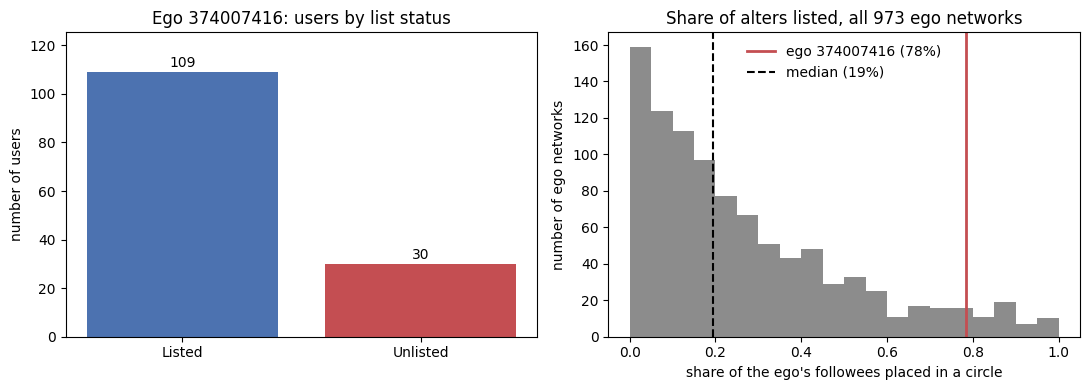

In [63]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

counts = nodes["list_status"].value_counts().reindex(["Listed", "Unlisted"])
ax[0].bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 2, str(v), ha="center")
ax[0].set(title=f"Ego {EGO}: users by list status",
          ylabel="number of users", ylim=(0, counts.max() * 1.15))

share = egos_df.set_index("ego").loc[EGO, "listed_share"]
ax[1].hist(egos_df["listed_share"], bins=20, color="#8C8C8C")
ax[1].axvline(share, color="#C44E52", lw=2,
              label=f"ego {EGO} ({share:.0%})")
ax[1].axvline(egos_df["listed_share"].median(), color="black", ls="--",
              label=f"median ({egos_df['listed_share'].median():.0%})")
ax[1].set(title="Share of alters listed, all 973 ego networks",
          xlabel="share of the ego's followees placed in a circle",
          ylabel="number of ego networks")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.savefig("figures/list_status_counts.png", dpi=150)
plt.show()

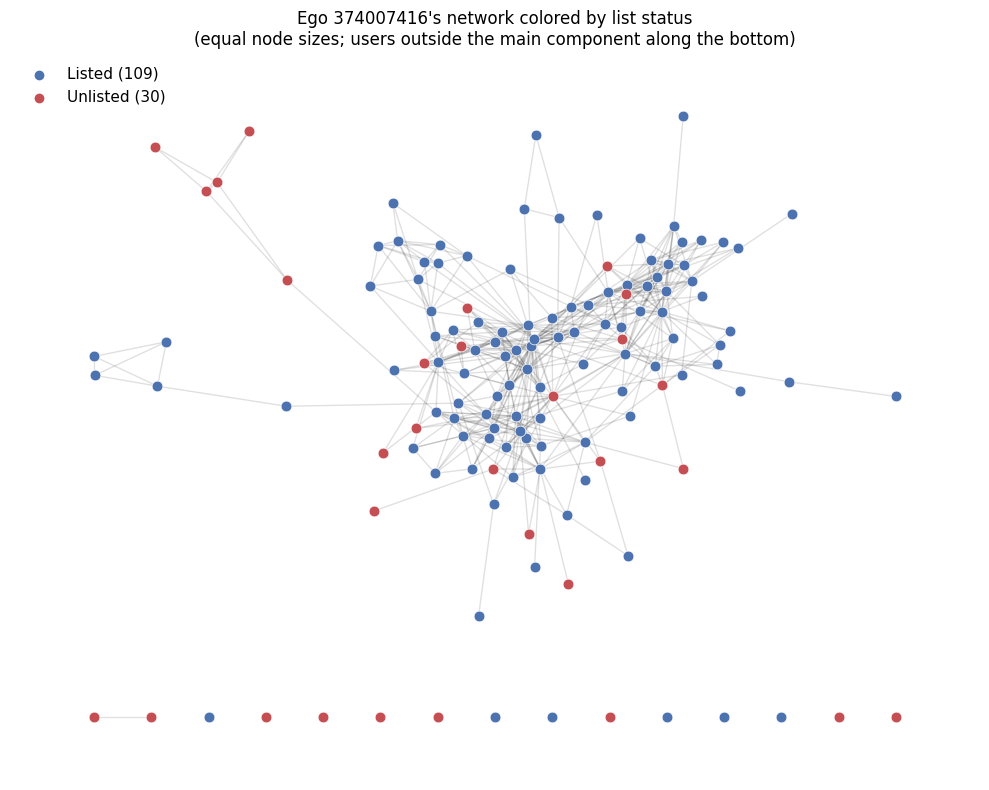

In [64]:
# The categorical variable on the network itself (no centrality calculated)
U = G.to_undirected()
main = U.subgraph(max(nx.connected_components(U), key=len))
pos = nx.spring_layout(main, seed=7, k=0.18)
others = [v for v in U if v not in main]
xs = [p[0] for p in pos.values()]
ybot = min(p[1] for p in pos.values()) - 0.25
for i, v in enumerate(others):
    pos[v] = (min(xs) + (max(xs) - min(xs)) * i / max(len(others) - 1, 1), ybot)

color = {"Listed": "#4C72B0", "Unlisted": "#C44E52"}
fig, ax = plt.subplots(figsize=(10, 8))
nx.draw_networkx_edges(U, pos, alpha=0.12, ax=ax)
for status, c in color.items():
    nl = [v for v in U if G.nodes[v]["list_status"] == status]
    ax.scatter([], [], color=c, label=f"{status} ({len(nl)})")
    nx.draw_networkx_nodes(U, pos, nodelist=nl, node_color=c, node_size=60,
                           edgecolors="white", linewidths=0.5, ax=ax)
ax.legend(loc="upper left", frameon=False, fontsize=11)
ax.set_title(f"Ego {EGO}'s network colored by list status\n"
             "(equal node sizes; users outside the main component along the "
             "bottom)")
ax.axis("off")
plt.tight_layout()
plt.savefig("figures/network_list_status.png", dpi=150)
plt.show()

**What the wider check shows**

- The download, extraction and labelling all work: the archive holds 973 ego networks
  (4,865 files, five per ego).
- Lists are common: 938 of the 973 egos put at least one of the people they follow on a
  list.
- Ego `374007416` is **not typical**. The ego listed 78 % of the people they follow, while
  the median ego network listed only 19 %. That is worth keeping in mind before
  generalising from this one network.

## Degree centrality in this network

What makes a node "important" depends on what a tie means. Here a tie means "A follows
B", so a follow is a choice to receive someone's tweets. Because the edges are directed,
degree centrality splits into two measures:

| Measure | What it captures | Meaning in this network | Role |
|---|---|---|---|
| **In-degree** centrality | number of incoming ties; finds the "celebrities" | how many other users in the group follow you (popularity) | **main measure** |
| Out-degree centrality | number of outgoing ties | how many in the group you follow (how active you are) | secondary |

- `networkx.in_degree_centrality` and `out_degree_centrality` divide each count by
  *n − 1* (138 here), so a score of 0.10 means about 10 % of the other users.
- The 13 isolated users have a degree of 0. That is real information about them, so they
  stay in the comparison.
- Centrality measures say who is central, not why. The comparison only asks whether the
  two groups differ.

## Questions and the hypothetical outcome

**Main question.** Do the users the ego put on a list have a higher in-degree centrality
(more followers inside the group) than the users the ego left off every list?

**Hypothetical outcome to predict: being added to one of the ego's lists.** Being listed is
a positive outcome for a user: it means the ego has chosen to curate that account into a
group they read. Staying unlisted is the negative outcome. If Listed users have clearly
higher in-degree centrality than Unlisted users, then in-degree could be used to predict
whether the ego will put a newly followed account on a list. This is close to what the
dataset was originally built for: discovering circles automatically from network
structure and profile features.

**Why I expect Listed users to be more central**

- *Homophily.* People tend to connect with people like themselves ("birds of a feather
  flock together"). If the ego builds lists around shared interests, the people on a list
  should also follow each other, which raises their in-degree.
- *Week 3 evidence.* Last week every circle with five or more members was 3 to 12 times
  denser inside than the network as a whole, so circle members are tightly connected to
  each other.
- *Embeddedness.* Twitter activity during the 2011 Egyptian revolution showed that being
  embedded in a dense cluster of like-minded people predicted influence (reactions per
  tweet) better than a large follower count.

**Why the answer could be "no"**

- In Week 3 the most followed user in the group (`20536157`, 20 followers in the group)
  follows nobody back and is **not on any list**. If the ego lists friends and leaves
  "broadcaster" accounts unlisted, the most popular users could sit in the Unlisted group.
  Comparing out-degree as well as in-degree will show whether listing tracks mutual,
  active relationships rather than popularity.

**How the comparison would work.** Compute in-degree centrality for every user, then
compare the average for Listed users with the average for Unlisted users. A clearly
higher average for Listed users would support using in-degree to predict who gets listed;
similar averages would mean in-degree is not a useful predictor here.

**Hypotheses**

| | Statement |
|---|---|
| H1 | Mean in-degree centrality is higher for Listed users than for Unlisted users. |
| H2 | Listed users also have higher out-degree centrality (they follow more of the group), which would point to mutual, active relationships rather than popularity alone. |
| H3 (secondary) | Photography taggers have higher in-degree centrality than other users in this photography-centred network, i.e. the community's main topic sits at its core. |

The null hypothesis for each is that there is no difference between the groups.

## Limitations

- **Old data.** The crawl was published in 2012, so it reflects Twitter at that time.
- **Anonymised IDs.** Users are numbers, so interpretation relies on hashtags and circles.
- **Lists reflect one person's choices.** Circles are the ego's own lists, and egos use
  them very differently (78 % listed here vs. a median of 19 %).
- **Missing features.** 20 users in this network have no features, which weakens the
  photography variable.
- **Association, not cause.** Even if Listed users are more central, being central may not
  be *why* they were listed; both could come from shared interests with the ego.
- **The ego is excluded.** This is deliberate (Week 3), but it means degree only counts
  follows among the alters, not each user's full Twitter audience.

## References

- McAuley, J. and Leskovec, J. (2012). *Learning to Discover Social Circles in Ego
  Networks.* Advances in Neural Information Processing Systems (NIPS).
- Stanford Network Analysis Project (SNAP). *Social circles: Twitter.*
  <https://snap.stanford.edu/data/ego-Twitter.html>
- Tsvetovat, M. and Kouznetsov, A. (2011). *Social Network Analysis for Startups.*
  O'Reilly Media.